# 미추홀구 I-MOD | 286개 정류장군 전체 EDA 및 상관분석

**분석기간:** 2026-04-01 ~ 2026-06-30 (2026-06-11 의도적 제외, 총 90일)  
**분석 단위:** 286개 정류장명 기반 Stop Group, 일·시간 617,760행  
**목표:** 품질 검증 → 파생변수 산출 → 분포·이상치 → 시간·요일·월별 패턴 → Pearson/Spearman 상관 → K-Means 후보변수 점검

이 노트북은 분석·검증 전용으로 **이상치 삭제, 결측 노선 수 0 대체, K-Means 실행을 하지 않습니다.** 지도 문제는 분석 범위에서 제외합니다.

필요 파일 2개:
1. `01_StopGroup_Features_With_Routes_2026Q2.csv` (고유 노선 수가 포함된 286행 Features)
2. `04_StopGroup_Hourly_2026Q2.csv` (617,760행 Hourly)

두 파일은 기존 `Michuhol_IMOD_RouteCount_2026Q2.zip`, `Michuhol_IMOD_StopGroups_2026Q2.zip` 안에 각각 있습니다.

In [5]:
import os, io, re, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", font_scale=0.95)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 80)
OUT = Path("IMOD_EDA_Results")
OUT.mkdir(exist_ok=True)

def savefig(name):
    plt.savefig(OUT / name, dpi=180, bbox_inches="tight")
    plt.show()

print("pandas", pd.__version__, "| 결과 저장 폴더:", OUT.resolve())

pandas 2.2.3 | 결과 저장 폴더: /content/IMOD_EDA_Results


## 1. 파일 업로드 (같은 이름 재업로드 문제 해결)
코랩에는 CSV 두 개를 동시에 올리세요. `(1).csv`처럼 이름이 바뀌어도 **실제 업로드 딕셔너리의 키를 찾아서** 읽습니다. 기존 런타임 파일을 읽으려면 `files.upload()` 대신 파일 경로를 지정해도 됩니다.

In [6]:
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    uploaded = {}
    print("로컬 실행: /mnt/data 등의 지정 경로에서 파일 탐색")

# upload가 없으면 로컬 검증/이미 올린 파일을 자동 탐색
file_paths = {}
def read_input(marker):
    matches = [(k, v) for k, v in uploaded.items() if marker in k and k.lower().endswith('.csv')]
    if matches:
        name, payload = matches[-1]
        file_paths[marker] = name
        return pd.read_csv(io.BytesIO(payload), encoding='utf-8-sig', low_memory=False)
    candidates = [p for p in list(Path('.').glob('*.csv')) + list(Path('/mnt/data/IMOD_Route_Features_2026Q2').glob('*.csv')) + list(Path('/mnt/data/IMOD_StopGroups_2026Q2').glob('*.csv')) if marker in p.name]
    if not candidates:
        raise FileNotFoundError(f'업로드 파일을 찾지 못했습니다: {marker}')
    path = sorted(candidates, key=lambda p: p.stat().st_mtime)[-1]
    file_paths[marker] = str(path)
    return pd.read_csv(path, encoding='utf-8-sig', low_memory=False)

features = read_input('StopGroup_Features_With_Routes')
hourly = read_input('StopGroup_Hourly')
print('입력:', file_paths)
print('Features:', features.shape, '| Hourly:', hourly.shape)
display(features.head(3))
display(hourly.head(3))

Saving 01_StopGroup_Features_With_Routes_2026Q2.csv to 01_StopGroup_Features_With_Routes_2026Q2 (2).csv
Saving 04_StopGroup_Hourly_2026Q2.csv to 04_StopGroup_Hourly_2026Q2.csv
입력: {'StopGroup_Features_With_Routes': '01_StopGroup_Features_With_Routes_2026Q2 (2).csv', 'StopGroup_Hourly': '04_StopGroup_Hourly_2026Q2.csv'}
Features: (286, 31) | Hourly: (617760, 25)


,station_name,observed_days,observed_hours,avg_daily_passengers,avg_daily_operations,passengers_per_operation,demand_cv_hour_profile,temporal_mismatch,low_supply_hour_ratio_lt1avg,positive_demand_zero_supply_record_count,station_id,station_no,latitude,longitude,admin_dong,spatial_match_status,station_name_id_count,stop_group_id,spatial_group_status,physical_cluster_count,representative_latitude,representative_longitude,representative_admin_dong,physical_station_count,spatial_confidence,unique_route_count,matched_route_stop_rows,matched_physical_stops,route_names,route_ids,route_count_status
0,(주)세모입구(린나이코리아),90,2160,58.577778,179.833333,0.325734,1.156311,0.356517,0.208333,0,ICB363000585,37585.0,37.472572,126.684816,주안5동,unique_station_name,1,SG001,single_stop,1,37.472572,126.684816,주안5동,1,high,1.0,1.0,1.0,510,165000072,matched_20260630
1,6공단사거리,90,2160,8.377778,189.222222,0.044275,0.848487,0.255365,0.208333,2,ICB363000577,37577.0,37.474062,126.667830,도화2·3동,unique_station_name,1,SG002,single_stop,1,37.474062,126.667830,도화2·3동,1,high,3.0,3.0,1.0,28; 510; 566,165000030; 165000072; 165000113,matched_20260630
2,6공단입구,90,2160,47.066667,328.622222,0.143224,0.819802,0.226813,0.208333,1,NaN,NaN,NaN,NaN,NaN,ambiguous_multiple_station_ids,2,SG003,nearby_stop_group,1,37.469691,126.679891,주안5동,2,medium,3.0,6.0,2.0,01월 28일; 28; 566,165000030; 165000113; 165000196,matched_20260630


,date,station_name,hour,passenger_count,operation_count,passengers_per_operation,ratio_defined,passenger_positive_operation_zero,station_id,station_no,latitude,longitude,admin_dong,spatial_match_status,station_name_id_count,source_row_count_ride,source_row_count_operations,stop_group_id,spatial_group_status,physical_cluster_count,representative_latitude,representative_longitude,representative_admin_dong,physical_station_count,spatial_confidence
0,20260401,(주)세모입구(린나이코리아),0,0,0,NaN,0,0,ICB363000585,37585.0,37.472572,126.684816,주안5동,unique_station_name,1,2,2,SG001,single_stop,1,37.472572,126.684816,주안5동,1,high
1,20260401,(주)세모입구(린나이코리아),1,0,0,NaN,0,0,ICB363000585,37585.0,37.472572,126.684816,주안5동,unique_station_name,1,2,2,SG001,single_stop,1,37.472572,126.684816,주안5동,1,high
2,20260401,(주)세모입구(린나이코리아),2,0,0,NaN,0,0,ICB363000585,37585.0,37.472572,126.684816,주안5동,unique_station_name,1,2,2,SG001,single_stop,1,37.472572,126.684816,주안5동,1,high


## 2. 필수 컬럼·분석 단위·결측 검증
같은 정류장명의 서로 다른 물리적 ID는 한 정류장군으로 간주합니다. 날짜·정류장명·시간의 중복은 확인하되 임의 합치지 않습니다.

In [7]:
core_f = ['station_name','avg_daily_passengers','avg_daily_operations', 'passengers_per_operation','demand_cv_hour_profile','temporal_mismatch','low_supply_hour_ratio_lt1avg','unique_route_count']
core_h = ['date','station_name','hour','passenger_count','operation_count']
for label, data, cols in [('Features',features,core_f),('Hourly',hourly,core_h)]:
    missing=[c for c in cols if c not in data.columns]
    if missing: raise ValueError(f'{label} 필수 컬럼 누락: {missing}')

features['station_name'] = features['station_name'].astype(str).str.strip()
hourly['station_name'] = hourly['station_name'].astype(str).str.strip()
hourly['date'] = pd.to_datetime(hourly['date'].astype(str).str.replace(r'\.0$','',regex=True), format='%Y%m%d', errors='raise')
hourly['hour'] = pd.to_numeric(hourly['hour'],errors='raise').astype(int)
for c in ['passenger_count','operation_count']:
    hourly[c] = pd.to_numeric(hourly[c], errors='coerce')

qc = {
    'feature_rows':len(features), 'unique_feature_stations':features.station_name.nunique(),
    'hourly_rows':len(hourly), 'unique_hourly_stations':hourly.station_name.nunique(),
    'observed_dates':hourly.date.nunique(), 'duplicate_feature_names':int(features.station_name.duplicated().sum()),
    'duplicate_date_station_hour':int(hourly.duplicated(['date','station_name','hour']).sum()),
    'passenger_missing_rows':int(hourly.passenger_count.isna().sum()),
    'operations_missing_rows':int(hourly.operation_count.isna().sum()),
    'negative_passenger_rows':int((hourly.passenger_count<0).sum()),
    'negative_operation_rows':int((hourly.operation_count<0).sum()),
    'positive_passenger_zero_operation_rows':int(((hourly.passenger_count>0)&(hourly.operation_count==0)).sum()),
    'date_2026_06_11_rows':int((hourly.date==pd.Timestamp('2026-06-11')).sum())
}
summary_qc=pd.Series(qc,name='value').to_frame()
display(summary_qc)
summary_qc.to_csv(OUT/'01_quality_summary.csv',encoding='utf-8-sig')
assert qc['duplicate_feature_names']==0, 'Features에 정류장명 중복이 있습니다'
assert qc['duplicate_date_station_hour']==0, 'Hourly 기본키 중복이 있습니다'
print('검증 기간:', hourly.date.min().date(), '~', hourly.date.max().date())
print('관측날짜 수:', hourly.date.nunique())
expected = features.station_name.nunique()*hourly.date.nunique()*24
print('기대 행 수:',expected, '| 실제 행 수:',len(hourly), '| 동일:',expected==len(hourly))
print('Features와 Hourly 이름집합 동일:',set(features.station_name)==set(hourly.station_name))

,value
feature_rows,286
unique_feature_stations,286
hourly_rows,617760
unique_hourly_stations,286
observed_dates,90
duplicate_feature_names,0
duplicate_date_station_hour,0
passenger_missing_rows,0
operations_missing_rows,0
negative_passenger_rows,0


검증 기간: 2026-04-01 ~ 2026-06-30
관측날짜 수: 90
기대 행 수: 617760 | 실제 행 수: 617760 | 동일: True
Features와 Hourly 이름집합 동일: True


## 3. 기존 수요·공급 지표 재현성 점검
Hourly의 일별 합계를 다시 평균하여 Features와 비교합니다. 소수점 반올림을 고려해 차이를 출력합니다. `observed_days`는 90일이어야 합니다.

In [8]:
daily = hourly.groupby(['station_name','date'],as_index=False)[['passenger_count','operation_count']].sum(min_count=1)
recalc = daily.groupby('station_name')[['passenger_count','operation_count']].mean().rename(columns={'passenger_count':'recalc_avg_daily_passengers','operation_count':'recalc_avg_daily_operations'})
check = features[['station_name','avg_daily_passengers','avg_daily_operations']].merge(recalc,left_on='station_name',right_index=True,validate='one_to_one')
check['passenger_abs_diff']=(check.avg_daily_passengers-check.recalc_avg_daily_passengers).abs()
check['operation_abs_diff']=(check.avg_daily_operations-check.recalc_avg_daily_operations).abs()
print('승차량 최대 절대 차이:',check.passenger_abs_diff.max())
print('운행횟수 최대 절대 차이:',check.operation_abs_diff.max())
display(check.sort_values('passenger_abs_diff',ascending=False).head(8))
check.to_csv(OUT/'02_recalculation_audit.csv',index=False,encoding='utf-8-sig')

승차량 최대 절대 차이: 4.444445949047804e-07
운행횟수 최대 절대 차이: 4.444445949047804e-07


,station_name,avg_daily_passengers,avg_daily_operations,recalc_avg_daily_passengers,recalc_avg_daily_operations,passenger_abs_diff,operation_abs_diff
67,롯데백화점(인천터미널),10306.455556,2553.288889,10306.455556,2553.288889,4.444446e-07,1.111111e-07
126,시민공원(문화창작지대)역,2216.855556,1174.811111,2216.855556,1174.811111,4.444446e-07,1.111111e-07
284,힐스테이트학익,404.755556,1314.744444,404.755556,1314.744444,4.444445e-07,4.444446e-07
40,대동아파트,468.555556,524.688889,468.555556,524.688889,4.444445e-07,1.111111e-07
37,남인천새마을금고중앙지점,358.444444,832.166667,358.444444,832.166667,4.444445e-07,3.333333e-07
254,토지금고,415.944444,407.700000,415.944444,407.700000,4.444445e-07,0.000000e+00
262,학산소극장,936.055556,652.933333,936.055556,652.933333,4.444445e-07,3.333333e-07
72,문학고개,299.444444,382.733333,299.444444,382.733333,4.444445e-07,3.333333e-07


## 4. 파생변수 추가 — 주말/평일 수요 비율
시간대별 데이터를 **일별 정류장군 승차량으로 합산한 후** 평일/주말 평균을 구합니다. 평일 평균이 0이면 비율은 결측 처리하며, 임의로 0이나 1로 대체하지 않습니다.

In [9]:
daily['is_weekend']=daily.date.dt.dayofweek>=5
wk = daily.groupby(['station_name','is_weekend'])['passenger_count'].mean().unstack().reindex(columns=[False, True])
wk.columns=['weekday_daily_mean','weekend_daily_mean']
wk['weekend_weekday_demand_ratio']=(wk.weekend_daily_mean/wk.weekday_daily_mean.replace(0,np.nan))
expanded = features.drop(columns=['weekend_weekday_demand_ratio'],errors='ignore').merge(wk.reset_index(),on='station_name',how='left',validate='one_to_one')
print('주말/평일 비율 결측:',expanded.weekend_weekday_demand_ratio.isna().sum())
print('고유 노선 수 결측:',expanded.unique_route_count.isna().sum())
display(expanded[['station_name','weekday_daily_mean','weekend_daily_mean','weekend_weekday_demand_ratio','unique_route_count']].head(10))
expanded.to_csv(OUT/'03_features_expanded_286.csv',index=False,encoding='utf-8-sig')

주말/평일 비율 결측: 0
고유 노선 수 결측: 2


,station_name,weekday_daily_mean,weekend_daily_mean,weekend_weekday_demand_ratio,unique_route_count
0,(주)세모입구(린나이코리아),74.656250,19.000000,0.254500,1.0
1,6공단사거리,9.296875,6.115385,0.657789,3.0
2,6공단입구,55.078125,27.346154,0.496498,3.0
3,JC회관,163.531250,82.307692,0.503315,4.0
4,KT인천지사,551.171875,349.500000,0.634103,2.0
5,LH미추홀3단지,361.046875,265.576923,0.735575,3.0
6,SK스카이뷰,9.718750,6.846154,0.704427,1.0
7,SK스카이뷰104동,272.890625,182.153846,0.667498,1.0
8,SK스카이뷰109동,282.265625,196.961538,0.697788,1.0
9,e편한세상주안에듀서밋아파트,163.187500,74.307692,0.455352,2.0


## 5. 변수 분포·기술통계·IQR 이상치
상관분석용 **핵심 8변수**를 사용합니다. `positive_demand_zero_supply_record_count`는 운영 수요 지표가 아니라 품질점검 변수이므로 별도로 관찰합니다. `unique_route_count` 결측 2개는 그대로 둡니다.

,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max,missing,skew,iqr_outlier_count
avg_daily_passengers,286.0,525.130,999.191,0.022,22.811,77.300,266.811,540.650,1136.878,1891.922,4547.463,10306.456,0,5.874,23
avg_daily_operations,286.0,476.400,405.752,24.967,85.994,170.842,371.767,673.439,962.261,1258.217,1616.609,2734.922,0,1.783,10
passengers_per_operation,286.0,0.882,0.904,0.001,0.166,0.412,0.715,1.129,1.646,1.905,3.941,11.463,0,6.291,11
demand_cv_hour_profile,286.0,0.882,0.267,0.596,0.681,0.720,0.803,0.965,1.180,1.343,1.749,3.317,0,3.716,16
temporal_mismatch,286.0,0.219,0.087,0.088,0.140,0.164,0.194,0.249,0.335,0.377,0.468,0.863,0,2.425,15
low_supply_hour_ratio_lt1avg,286.0,0.199,0.031,0.125,0.167,0.167,0.208,0.208,0.250,0.250,0.256,0.375,0,0.474,3
weekend_weekday_demand_ratio,286.0,0.605,0.201,0.067,0.396,0.516,0.621,0.690,0.756,0.818,1.111,2.462,0,2.945,15
unique_route_count,284.0,4.785,3.980,1.000,1.000,2.000,4.000,7.000,9.000,12.850,17.000,26.000,2,1.850,10


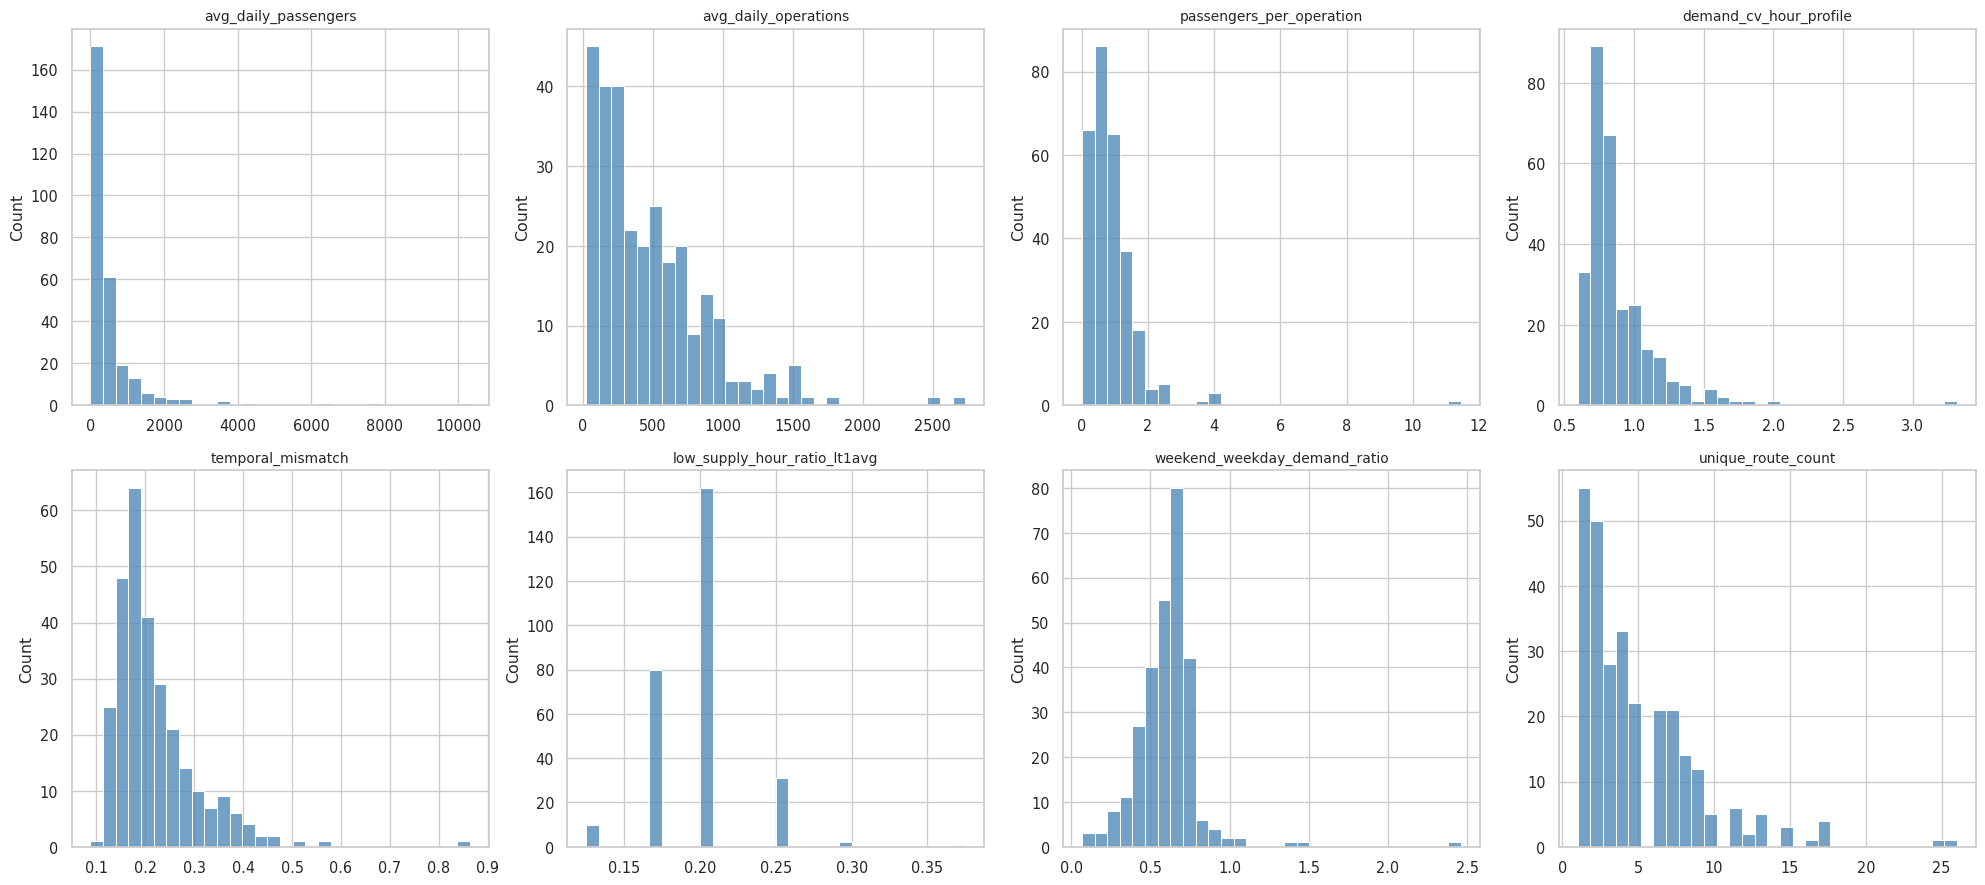

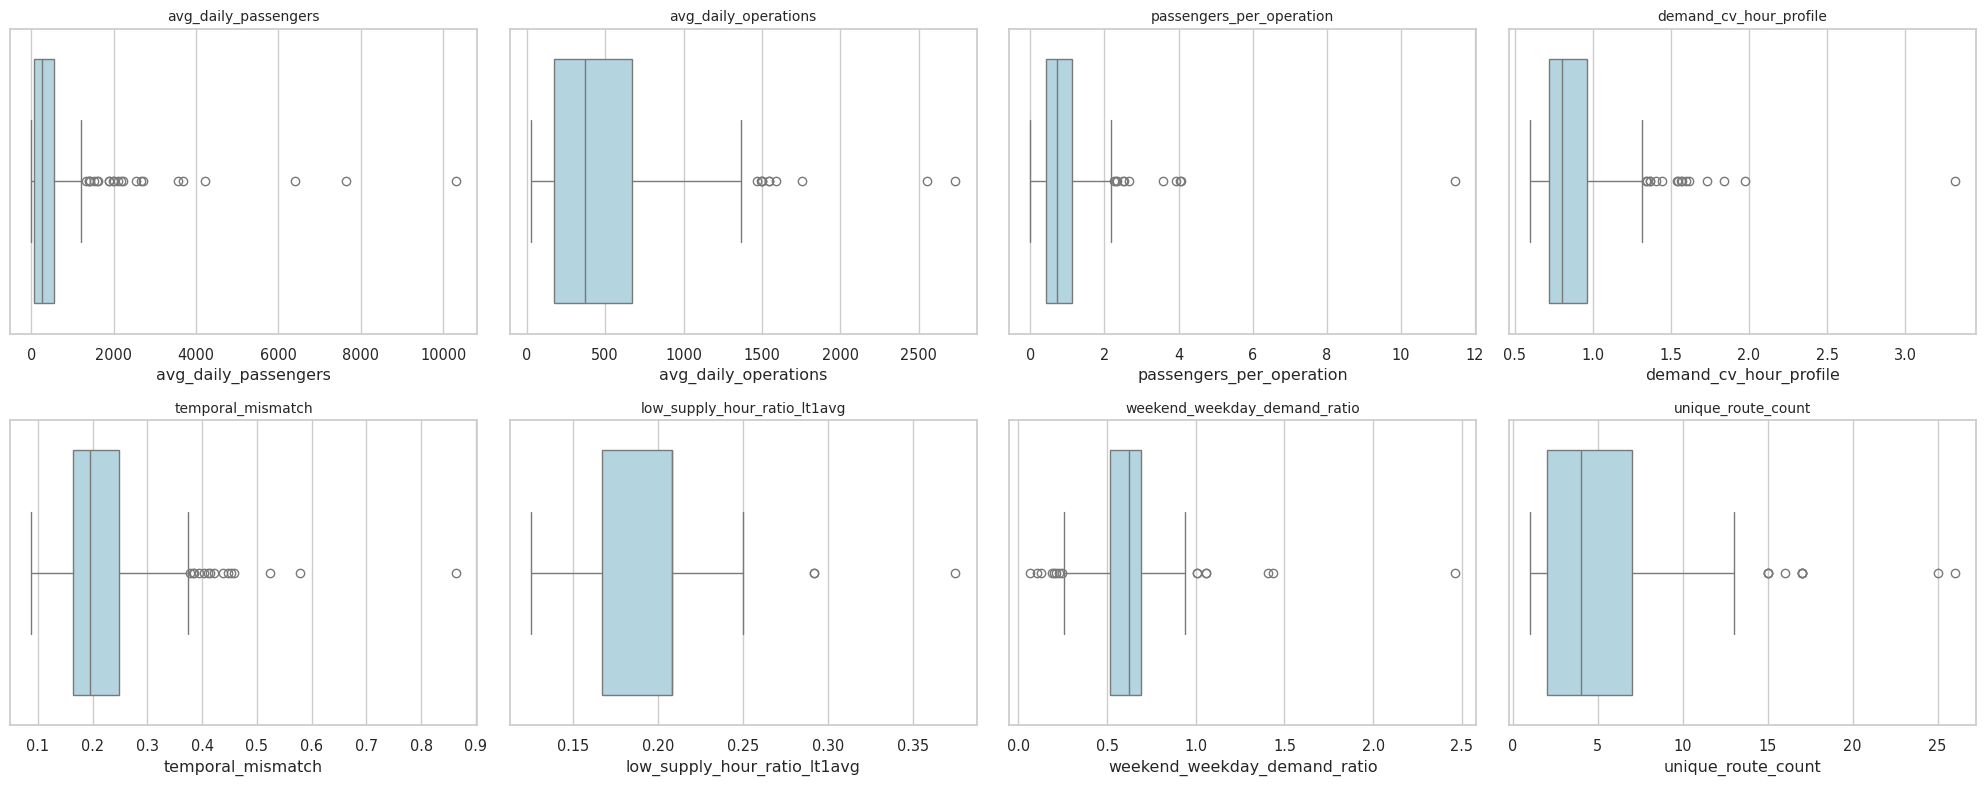

In [10]:
variables = [
'avg_daily_passengers','avg_daily_operations','passengers_per_operation',
'demand_cv_hour_profile','temporal_mismatch','low_supply_hour_ratio_lt1avg',
'weekend_weekday_demand_ratio','unique_route_count']
X=expanded[variables].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan)
desc=X.describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]).T
desc['missing']=X.isna().sum()
desc['skew']=X.skew()
q1=X.quantile(.25);q3=X.quantile(.75);iqr=q3-q1
lo=q1-1.5*iqr;hi=q3+1.5*iqr
outlier_mask=(X.lt(lo)|X.gt(hi))
desc['iqr_outlier_count']=outlier_mask.sum()
display(desc.round(3))
desc.to_csv(OUT/'04_feature_descriptives.csv',encoding='utf-8-sig')
fig,axs=plt.subplots(2,4,figsize=(20,9))
for ax,c in zip(axs.flat,variables):
    sns.histplot(X[c].dropna(),bins=30,ax=ax,color='steelblue')
    ax.set_title(c,fontsize=10);ax.set_xlabel('')
plt.tight_layout();savefig('05_feature_histograms.png')
fig,axs=plt.subplots(2,4,figsize=(20,8))
for ax,c in zip(axs.flat,variables):
    sns.boxplot(x=X[c],ax=ax,color='lightblue');ax.set_title(c,fontsize=10)
plt.tight_layout();savefig('06_feature_boxplots.png')

## 6. 수요·공급 시간대별 패턴 (전체 + 평일/주말)
시간대별 평균은 **정류장군×일자 한 건의 평균**입니다. 단순 총합과 다른 통계이므로 축과 단위를 확인합니다.

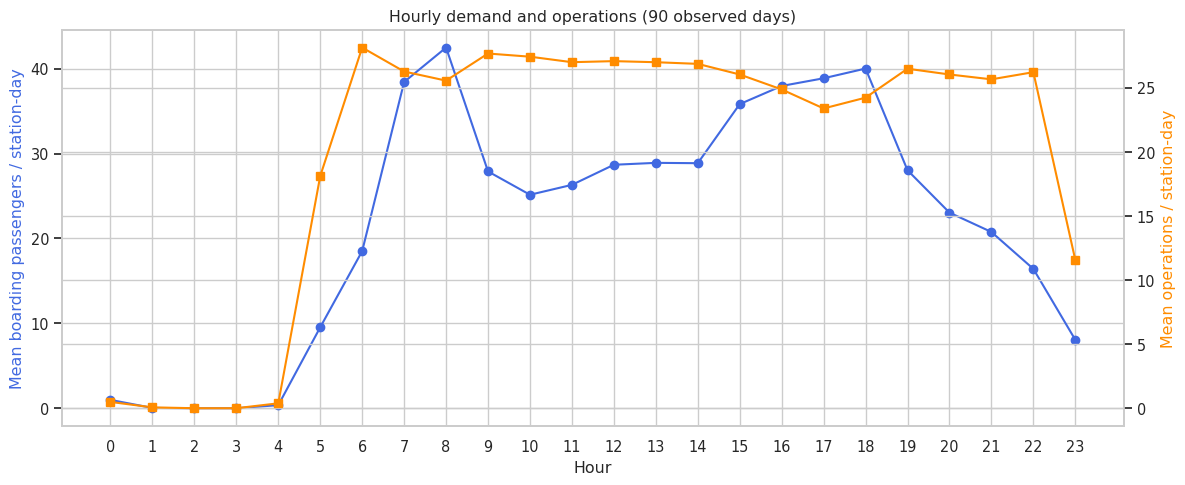

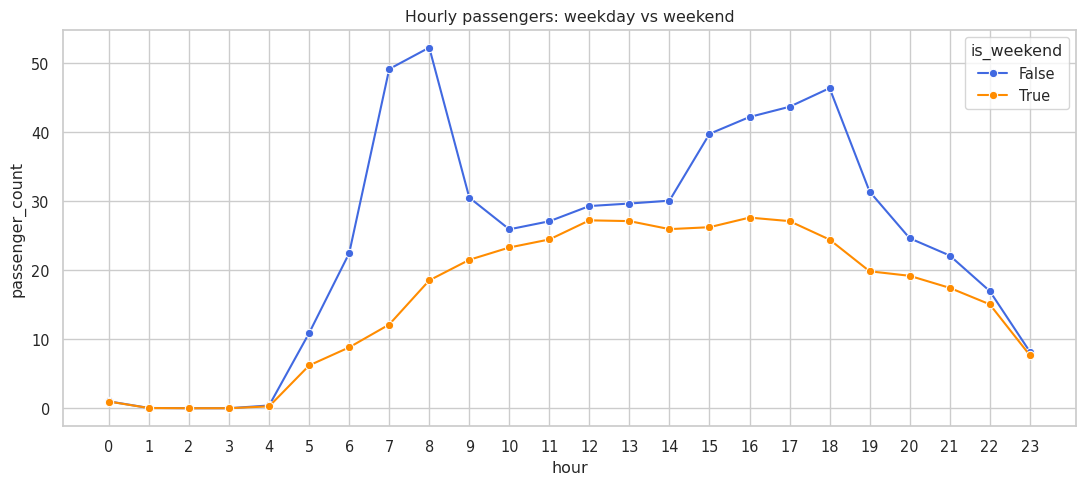

In [11]:
hour_profile=hourly.groupby('hour')[['passenger_count','operation_count']].agg(['mean','sum'])
hour_profile.columns=['passenger_mean','passenger_sum','operation_mean','operation_sum']
hour_profile=hour_profile.reset_index().sort_values('hour')
hour_profile.to_csv(OUT/'07_hourly_profile.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(12,5))
a2=ax.twinx();ax.plot(hour_profile.hour,hour_profile.passenger_mean,marker='o',label='Passengers',color='royalblue');a2.plot(hour_profile.hour,hour_profile.operation_mean,marker='s',label='Operations',color='darkorange')
ax.set_xlabel('Hour');ax.set_ylabel('Mean boarding passengers / station-day',color='royalblue');a2.set_ylabel('Mean operations / station-day',color='darkorange');ax.set_xticks(range(24));ax.set_title('Hourly demand and operations (90 observed days)')
plt.tight_layout();savefig('08_hourly_demand_operations.png')
hourly['is_weekend']=hourly.date.dt.dayofweek>=5
hwd=hourly.groupby(['hour','is_weekend'])['passenger_count'].mean().reset_index()
fig,ax=plt.subplots(figsize=(11,5));sns.lineplot(data=hwd,x='hour',y='passenger_count',hue='is_weekend',marker='o',ax=ax,palette=['royalblue','darkorange']);ax.set_xticks(range(24));ax.set_title('Hourly passengers: weekday vs weekend');plt.tight_layout();savefig('09_hourly_weekday_weekend.png')

## 7. 월별·요일별 패턴 — 관측일 수로 보정
4~6월은 월별 관측일 수가 다르므로 **단순 총합과 일평균**을 함께 표기합니다. 요일별도 해당 요일의 관측일 수를 분모로 사용합니다.

,month,observed_days,passenger_total,operation_total,passenger_mean_daily,operation_mean_daily
0,2026-04,30,4656108,4184711,155203.600000,139490.366667
1,2026-05,31,4524288,4109270,145944.774194,132557.096774
2,2026-06,29,4336451,3968552,149532.793103,136846.620690


,weekday,observed_days,passenger_mean_daily,operation_mean_daily
0,0,13,160245.846154,146205.230769
1,1,13,164722.692308,146128.076923
2,2,13,166937.153846,146257.538462
3,3,12,171163.000000,149486.416667
4,4,13,172013.769231,145800.538462
5,5,13,123675.461538,116029.692308
6,6,13,94165.923077,104863.230769


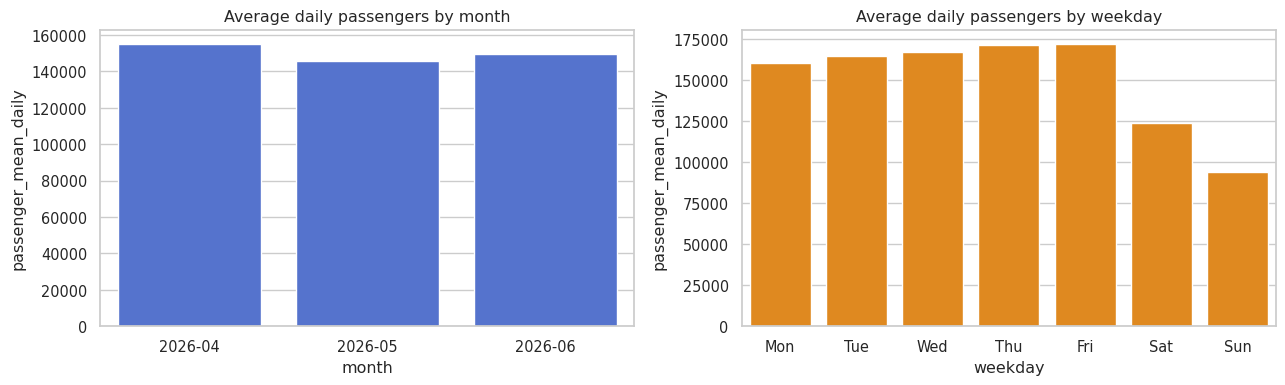

In [12]:
per_day=hourly.groupby('date',as_index=False)[['passenger_count','operation_count']].sum()
per_day['month']=per_day.date.dt.strftime('%Y-%m')
per_day['weekday']=per_day.date.dt.dayofweek
monthly=per_day.groupby('month').agg(observed_days=('date','nunique'),passenger_total=('passenger_count','sum'),operation_total=('operation_count','sum'),passenger_mean_daily=('passenger_count','mean'),operation_mean_daily=('operation_count','mean')).reset_index()
weekdays=per_day.groupby('weekday').agg(observed_days=('date','nunique'),passenger_mean_daily=('passenger_count','mean'),operation_mean_daily=('operation_count','mean')).reset_index()
display(monthly);display(weekdays)
monthly.to_csv(OUT/'10_monthly_statistics.csv',index=False,encoding='utf-8-sig')
weekdays.to_csv(OUT/'11_weekday_statistics.csv',index=False,encoding='utf-8-sig')
fig,axs=plt.subplots(1,2,figsize=(13,4));sns.barplot(data=monthly,x='month',y='passenger_mean_daily',ax=axs[0],color='royalblue');axs[0].set_title('Average daily passengers by month');sns.barplot(data=weekdays,x='weekday',y='passenger_mean_daily',ax=axs[1],color='darkorange');axs[1].set_xticks(range(7),['Mon','Tue','Wed','Thu','Fri','Sat','Sun']);axs[1].set_title('Average daily passengers by weekday');plt.tight_layout();savefig('12_month_weekday.png')

## 8. Pearson / Spearman 상관분석
`unique_route_count` 결측 2개를 가진 변수쌍은 기본적으로 **pairwise complete observations**로 계산합니다. 따라서 노선 수 관련 표본은 보통 284개, 다른 변수쌍은 최대 286개일 수 있습니다. 표본 수도 함께 저장합니다.

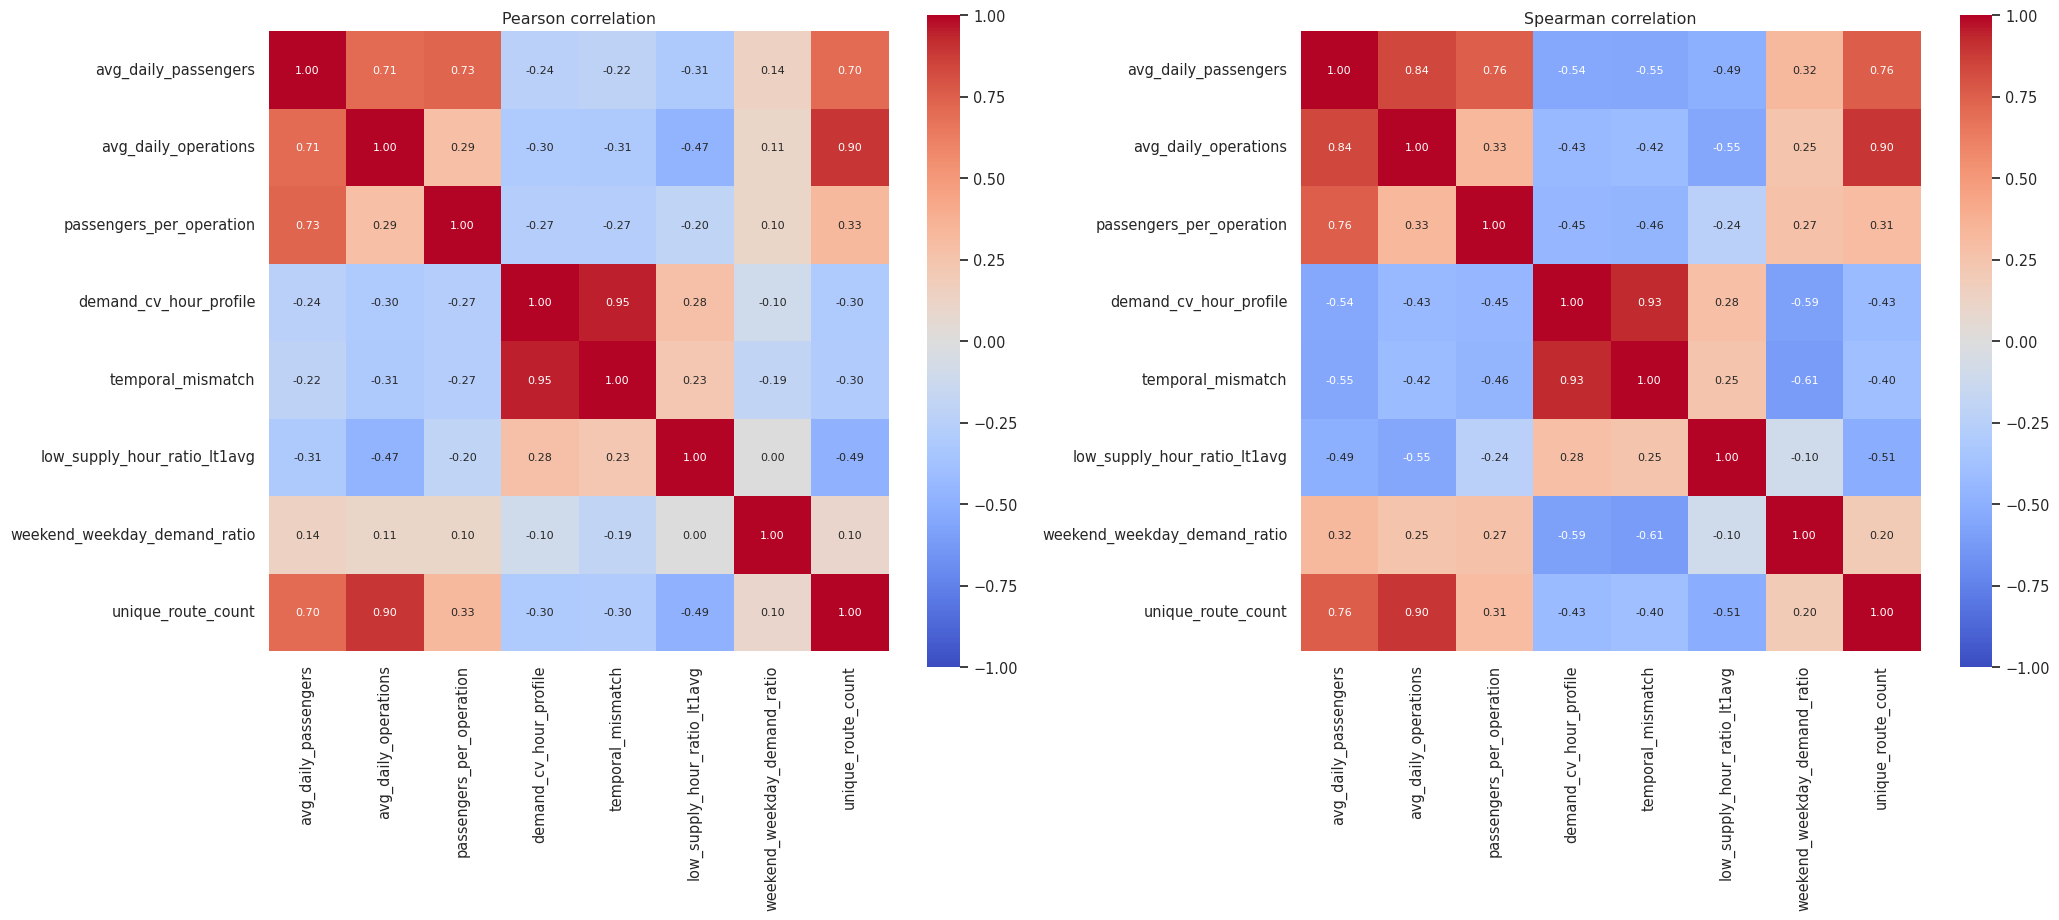

,variable_1,variable_2,pearson,spearman,abs_pearson_spearman_diff,n_pair,high_abs_corr_any
20,demand_cv_hour_profile,weekend_weekday_demand_ratio,-0.099843,-0.590776,0.490933,286,False
23,temporal_mismatch,weekend_weekday_demand_ratio,-0.191461,-0.613533,0.422072,286,False
3,avg_daily_passengers,temporal_mismatch,-0.216630,-0.554291,0.337660,286,False
2,avg_daily_passengers,demand_cv_hour_profile,-0.241393,-0.544446,0.303053,286,False
14,passengers_per_operation,temporal_mismatch,-0.270249,-0.464963,0.194714,286,False
4,avg_daily_passengers,low_supply_hour_ratio_lt1avg,-0.305386,-0.493614,0.188228,286,False
5,avg_daily_passengers,weekend_weekday_demand_ratio,0.137551,0.323665,0.186114,286,False
13,passengers_per_operation,demand_cv_hour_profile,-0.272209,-0.453068,0.180859,286,False
16,passengers_per_operation,weekend_weekday_demand_ratio,0.102526,0.268253,0.165727,286,False
11,avg_daily_operations,weekend_weekday_demand_ratio,0.105694,0.253965,0.148271,286,False


고유 노선 수 상관관계:


,variable_1,variable_2,pearson,spearman,abs_pearson_spearman_diff,n_pair,high_abs_corr_any
21,demand_cv_hour_profile,unique_route_count,-0.300555,-0.429356,0.128801,284,False
27,weekend_weekday_demand_ratio,unique_route_count,0.099368,0.202172,0.102804,284,False
24,temporal_mismatch,unique_route_count,-0.296266,-0.397110,0.100845,284,False
6,avg_daily_passengers,unique_route_count,0.704927,0.762616,0.057689,284,False
26,low_supply_hour_ratio_lt1avg,unique_route_count,-0.486133,-0.508165,0.022032,284,False
17,passengers_per_operation,unique_route_count,0.327487,0.309583,0.017904,284,False
12,avg_daily_operations,unique_route_count,0.895684,0.896879,0.001195,284,True


In [13]:
pearson=X.corr(method='pearson');spearman=X.corr(method='spearman')
n_pair = X.notna().astype(int).T.dot(X.notna().astype(int))
fig,axs=plt.subplots(1,2,figsize=(21,9))
for ax,corr,title in zip(axs,[pearson,spearman],['Pearson correlation','Spearman correlation']):
    sns.heatmap(corr,annot=True,fmt='.2f',cmap='coolwarm',center=0,vmin=-1,vmax=1,square=True,ax=ax,annot_kws={'size':8});ax.set_title(title)
plt.tight_layout();savefig('13_pearson_spearman_heatmaps.png')
pearson.to_csv(OUT/'14_pearson.csv',encoding='utf-8-sig')
spearman.to_csv(OUT/'15_spearman.csv',encoding='utf-8-sig')
n_pair.to_csv(OUT/'16_pairwise_sample_counts.csv',encoding='utf-8-sig')
rows=[]
for i,a in enumerate(variables):
 for c in variables[i+1:]:
    p,s=pearson.loc[a,c],spearman.loc[a,c]
    rows.append({'variable_1':a,'variable_2':c,'pearson':p,'spearman':s,'abs_pearson_spearman_diff':abs(p-s),'n_pair':int(n_pair.loc[a,c]),'high_abs_corr_any':(abs(p)>=.8 or abs(s)>=.8)})
comp=pd.DataFrame(rows).sort_values('abs_pearson_spearman_diff',ascending=False)
display(comp.head(20));comp.to_csv(OUT/'17_correlation_pair_comparison.csv',index=False,encoding='utf-8-sig')
print('고유 노선 수 상관관계:');display(comp[(comp.variable_1=='unique_route_count')|(comp.variable_2=='unique_route_count')])

## 9. 중요 관계 산점도 + 극단 정류장 확인
CV–Mismatch, 요일비율–Mismatch, 승차량–운행횟수, 노선 수–운행횟수를 실제 점 분포로 점검합니다. **상관관계는 인과관계가 아닙니다.**

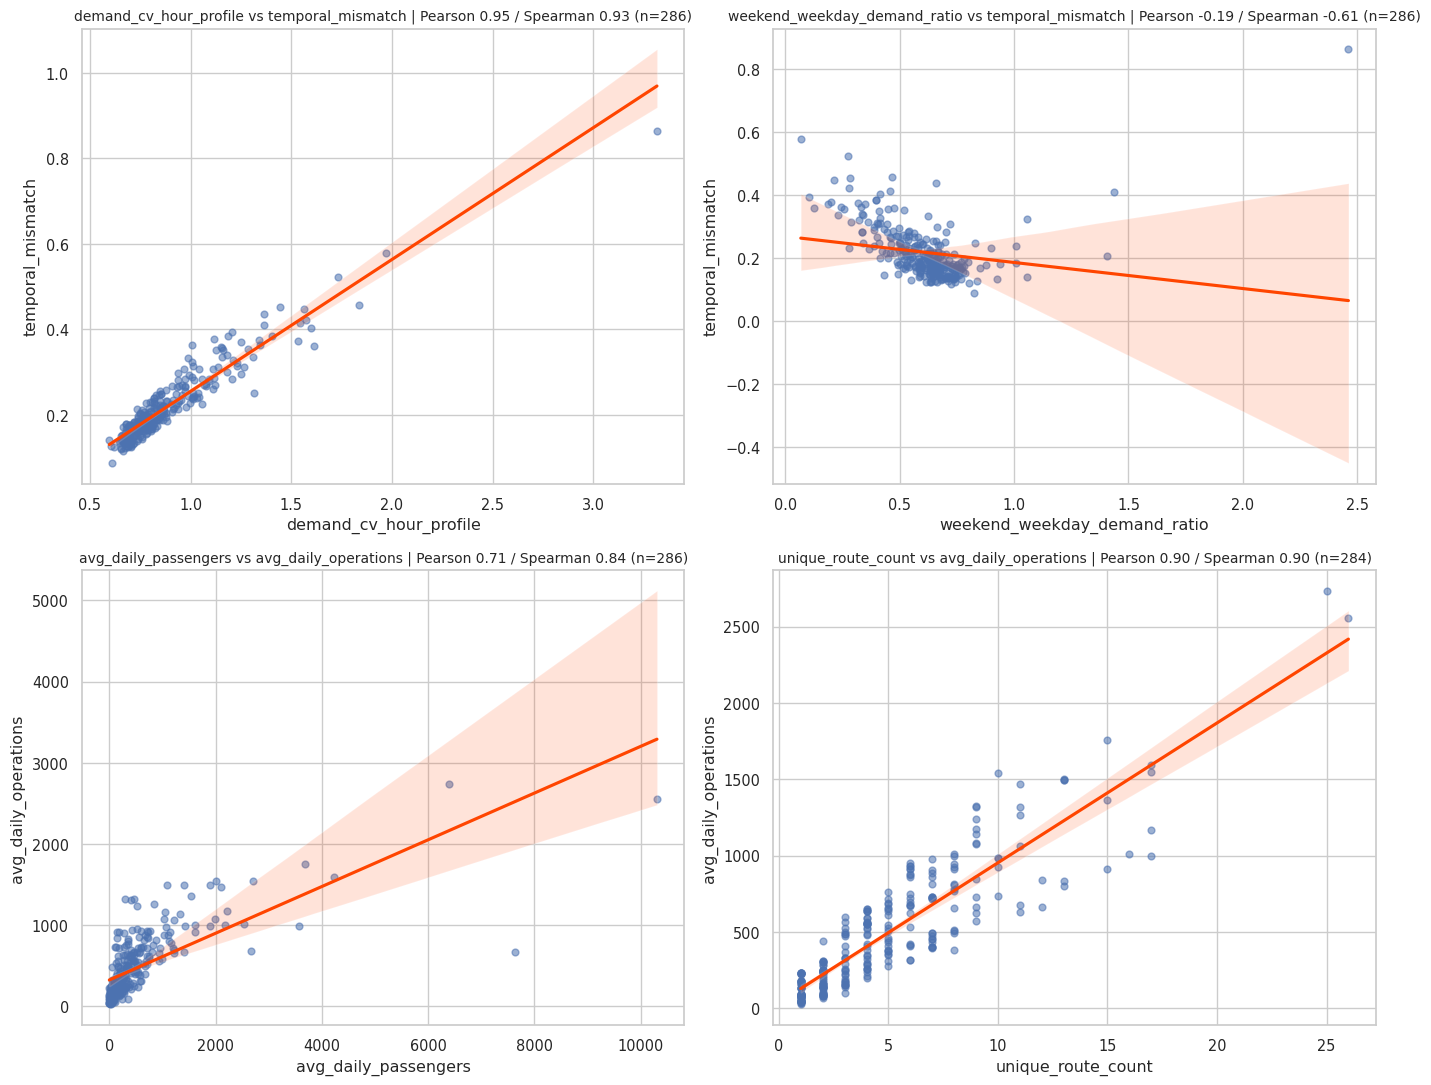

CV 상위 10곳:


,station_name,avg_daily_passengers,avg_daily_operations,passengers_per_operation,demand_cv_hour_profile,temporal_mismatch,low_supply_hour_ratio_lt1avg,weekend_weekday_demand_ratio,unique_route_count
25,국제이노베이션,0.022222,38.322222,0.000580,3.316625,0.863439,0.250000,2.461538,1.0
158,옥련여고입구,147.233333,913.322222,0.161206,1.971036,0.578860,0.166667,0.067369,8.0
169,용현동성원상떼빌아파트,2.788889,44.666667,0.062438,1.838200,0.457844,0.250000,0.466642,1.0
186,인천기계산업단지,23.288889,76.644444,0.303856,1.733409,0.523342,0.208333,0.272635,1.0
240,주안시범공단,10.066667,90.377778,0.111384,1.612693,0.360408,0.250000,0.125647,1.0
54,도화e편한세상아파트6단지,76.033333,148.655556,0.511473,1.597071,0.403725,0.208333,0.413898,3.0
233,주안국가산단역,242.333333,179.844444,1.347461,1.572086,0.422198,0.208333,0.279509,1.0
12,가좌테니스장,87.333333,251.711111,0.346959,1.561060,0.447072,0.208333,0.210426,2.0
184,인천교삼거리(인천기계산업단지),50.355556,254.833333,0.197602,1.543853,0.414683,0.208333,0.455745,4.0
244,주안역센트레빌아파트정문,34.411111,89.411111,0.384864,1.535871,0.372252,0.250000,0.349444,1.0


시간적 불일치 상위 10곳:


,station_name,avg_daily_passengers,avg_daily_operations,passengers_per_operation,demand_cv_hour_profile,temporal_mismatch,low_supply_hour_ratio_lt1avg,weekend_weekday_demand_ratio,unique_route_count
25,국제이노베이션,0.022222,38.322222,0.000580,3.316625,0.863439,0.250000,2.461538,1.0
158,옥련여고입구,147.233333,913.322222,0.161206,1.971036,0.578860,0.166667,0.067369,8.0
186,인천기계산업단지,23.288889,76.644444,0.303856,1.733409,0.523342,0.208333,0.272635,1.0
169,용현동성원상떼빌아파트,2.788889,44.666667,0.062438,1.838200,0.457844,0.250000,0.466642,1.0
15,경인방송,6.044444,170.811111,0.035387,1.444231,0.453060,0.208333,0.282472,1.0
12,가좌테니스장,87.333333,251.711111,0.346959,1.561060,0.447072,0.208333,0.210426,2.0
281,현광아파트후문앞,0.211111,140.833333,0.001499,1.363351,0.437214,0.208333,0.656410,2.0
233,주안국가산단역,242.333333,179.844444,1.347461,1.572086,0.422198,0.208333,0.279509,1.0
184,인천교삼거리(인천기계산업단지),50.355556,254.833333,0.197602,1.543853,0.414683,0.208333,0.455745,4.0
69,문학경기장(야구장),309.477778,456.133333,0.678481,1.365521,0.411426,0.208333,1.436866,7.0


In [14]:
pairs=[('demand_cv_hour_profile','temporal_mismatch'),('weekend_weekday_demand_ratio','temporal_mismatch'),('avg_daily_passengers','avg_daily_operations'),('unique_route_count','avg_daily_operations')]
fig,axs=plt.subplots(2,2,figsize=(14,11))
for ax,(a,c) in zip(axs.flat,pairs):
    d=expanded[[a,c]].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan).dropna()
    sns.regplot(data=d,x=a,y=c,ax=ax,scatter_kws={'alpha':.55,'s':24},line_kws={'color':'orangered'})
    ax.set_title(f'{a} vs {c} | Pearson {d[a].corr(d[c]):.2f} / Spearman {d[a].corr(d[c],method="spearman"):.2f} (n={len(d)})',fontsize=10)
plt.tight_layout();savefig('18_key_relationship_scatter.png')
cols=['station_name']+variables
print('CV 상위 10곳:');display(expanded[cols].sort_values('demand_cv_hour_profile',ascending=False).head(10))
print('시간적 불일치 상위 10곳:');display(expanded[cols].sort_values('temporal_mismatch',ascending=False).head(10))
expanded[cols].sort_values('temporal_mismatch',ascending=False).to_csv(OUT/'19_station_ranking_by_mismatch.csv',index=False,encoding='utf-8-sig')

## 10. 품질 플래그 별도 분석
승객수>0 & 운행횟수=0은 즉시 공급부족으로 판정할 수 없습니다. API 집계 시점 및 운행횟수 정의 문제도 가능하므로 품질검사 결과로 관리합니다.

In [15]:
mask=(hourly.passenger_count>0)&(hourly.operation_count==0)
quality_by_station=hourly.loc[mask].groupby('station_name').size().rename('positive_demand_zero_operation_rows').reset_index()
quality_by_station=expanded[['station_name']].merge(quality_by_station,how='left',on='station_name').fillna({'positive_demand_zero_operation_rows':0})
quality_by_station['positive_demand_zero_operation_rows']=quality_by_station['positive_demand_zero_operation_rows'].astype(int)
print('문제 행 총합:',int(mask.sum()))
display(quality_by_station.nlargest(15,'positive_demand_zero_operation_rows'))
quality_by_station.to_csv(OUT/'20_zero_operation_quality_flags.csv',index=False,encoding='utf-8-sig')

문제 행 총합: 3143


,station_name,positive_demand_zero_operation_rows
127,시민공원.문화창작지대,108
220,제물포역,97
246,주안파크자이더플래티넘아파트,88
226,조달청(한양2차아파트),79
97,서화초등학교(도화역금강펜테리움),77
161,용일사거리,77
67,롯데백화점(인천터미널),75
120,숭의역(2번출구),75
131,시티오씨엘3단지,71
214,정부인천지방합동청사,70


## 11. K-Means 전처리 후보군 제안 (분석만, 모델 학습 안 함)
- 수요·공급 규모: 평균 승차량, 운행횟수
- 이용강도: 운행당 승객수
- 시간 특성: `temporal_mismatch` 또는 `demand_cv_hour_profile` 비교
- 공급 취약: 저공급 시간 비율
- 요일 특성: 주말/평일 수요 비율
- 노선 접근성: 고유 노선 수 (`unique_route_count`)

결측값은 K-Means 실행 전에 처리 방식을 결정해야 합니다. 2개 미매칭 노선 수를 실제 0으로 취급하면 안 됩니다. 원본 기준 시간대별 저공급 지표와 불일치 지표는 **실제 대기시간이나 운송용량 부족을 뜻하지 않습니다.**

In [16]:
candidate_sets={
 'A_core_5':['avg_daily_passengers','avg_daily_operations','passengers_per_operation','temporal_mismatch','low_supply_hour_ratio_lt1avg'],
 'B_add_weekend_6':['avg_daily_passengers','avg_daily_operations','passengers_per_operation','temporal_mismatch','low_supply_hour_ratio_lt1avg','weekend_weekday_demand_ratio'],
 'C_add_routes_7':['avg_daily_passengers','avg_daily_operations','passengers_per_operation','temporal_mismatch','low_supply_hour_ratio_lt1avg','weekend_weekday_demand_ratio','unique_route_count'],
 'D_replace_mismatch_with_cv_7':['avg_daily_passengers','avg_daily_operations','passengers_per_operation','demand_cv_hour_profile','low_supply_hour_ratio_lt1avg','weekend_weekday_demand_ratio','unique_route_count']
}
model_candidates=pd.DataFrame([{'candidate':k,'n_variables':len(v),'n_complete_rows':int(X[v].dropna().shape[0]),'variables':', '.join(v)} for k,v in candidate_sets.items()])
display(model_candidates)
model_candidates.to_csv(OUT/'21_kmeans_candidate_variable_sets.csv',index=False,encoding='utf-8-sig')

,candidate,n_variables,n_complete_rows,variables
0,A_core_5,5,286,"avg_daily_passengers, avg_daily_operations, pa..."
1,B_add_weekend_6,6,286,"avg_daily_passengers, avg_daily_operations, pa..."
2,C_add_routes_7,7,284,"avg_daily_passengers, avg_daily_operations, pa..."
3,D_replace_mismatch_with_cv_7,7,284,"avg_daily_passengers, avg_daily_operations, pa..."


## 12. 결과 ZIP 다운로드
저장한 모든 CSV와 PNG를 한 번에 묶습니다. 파일 입력이 바뀌면 셀을 처음부터 다시 실행하세요.

In [17]:
outzip='Michuhol_IMOD_EDA_Full_2026Q2.zip'
with zipfile.ZipFile(outzip,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.iterdir()):
        if p.is_file(): z.write(p,arcname=p.name)
print('생성:',outzip,'| 파일 수:',len(list(OUT.iterdir())))
try:
    from google.colab import files
    files.download(outzip)
except ImportError:
    print('저장경로:',Path(outzip).resolve())

생성: Michuhol_IMOD_EDA_Full_2026Q2.zip | 파일 수: 21


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>